# Notebook 02 — EDA histórico AEMET (2020-2024)

Objetivo: Analizar la calidad, completitud y comportamiento temporal de los datos climatológicos obtenidos de AEMET para las estaciones seleccionadas.

Este análisis servirá para:
- detectar valores faltantes,
- evaluar la cobertura temporal de las estaciones,
- identificar episodios extremos,
- caracterizar el evento DANA dentro del contexto histórico reciente.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_parquet("../data/processed/aemet_historico_2020_2024.parquet")

print(f"Filas: {len(df):,}")
print(f"Columnas: {list(df.columns)}")
print(f"Estaciones: {df['indicativo'].nunique()}")
df.head()

Filas: 12,879
Columnas: ['fecha', 'indicativo', 'nombre', 'provincia', 'altitud', 'tmed', 'prec', 'tmin', 'horatmin', 'tmax', 'horatmax', 'dir', 'velmedia', 'racha', 'horaracha', 'sol', 'presMax', 'horaPresMax', 'presMin', 'horaPresMin', 'hrMedia', 'hrMax', 'horaHrMax', 'hrMin', 'horaHrMin', 'lat', 'lon', 'altitud_m']
Estaciones: 8


,fecha,indicativo,nombre,provincia,altitud,tmed,prec,tmin,horatmin,tmax,...,presMin,horaPresMin,hrMedia,hrMax,horaHrMax,hrMin,horaHrMin,lat,lon,altitud_m
0,2020-01-01,8025,ALACANT/ALICANTE,ALICANTE,81,10.3,0.0,4.3,07:40,16.3,...,1020.9,14,80.0,94.0,07:50,60.0,13:00,38.3725,-0.494167,81
1,2020-01-02,8025,ALACANT/ALICANTE,ALICANTE,81,10.2,0.0,5.5,23:59,14.9,...,1021.2,15,75.0,90.0,23:30,60.0,13:40,38.3725,-0.494167,81
2,2020-01-03,8025,ALACANT/ALICANTE,ALICANTE,81,9.0,0.0,2.6,07:10,15.5,...,1019.4,15,76.0,96.0,08:00,52.0,14:10,38.3725,-0.494167,81
3,2020-01-04,8025,ALACANT/ALICANTE,ALICANTE,81,10.6,0.0,5.4,07:10,15.8,...,1021.2,24,77.0,96.0,01:50,57.0,12:00,38.3725,-0.494167,81
4,2020-01-05,8025,ALACANT/ALICANTE,ALICANTE,81,10.8,0.0,3.6,07:10,18.0,...,1017.2,14,73.0,92.0,00:10,42.0,13:40,38.3725,-0.494167,81


## Evaluación de calidad y completitud


Se calcula el porcentaje de valores faltantes por estación para las variables meteorológicas más relevantes.

El objetivo es verificar si existen problemas de cobertura que puedan afectar posteriormente.

In [9]:
calidad = (
    df.groupby("indicativo")
      .agg(
          registros=("fecha", "count"),
          prec_faltante_pct=("prec", lambda x: x.isna().mean() * 100),
          tmed_faltante_pct=("tmed", lambda x: x.isna().mean() * 100),
          fecha_min=("fecha", "min"),
          fecha_max=("fecha", "max"),
      )
      .round(1)
)
calidad

C:\Users\Maria\AppData\Local\Temp\ipykernel_37936\1847942633.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(1)


,registros,prec_faltante_pct,tmed_faltante_pct,fecha_min,fecha_max
indicativo,,,,,
8025,1827,3.0,0.2,2020-01-01,2024-12-31
8058X,635,3.0,9.3,2020-01-01,2022-06-05
8175,1646,0.0,0.0,2020-01-01,2024-12-31
8203O,1467,3.4,3.0,2020-01-01,2024-12-31
8293X,1823,6.0,5.0,2020-01-01,2024-12-31
8414A,1827,0.0,0.0,2020-01-01,2024-12-31
8416Y,1827,0.4,1.7,2020-01-01,2024-12-31
8500A,1827,0.0,0.1,2020-01-01,2024-12-31


En la tabla se pueden visualizar el número de días de los que hay datos.

Cabe destacar el caso de 8058X (Oliva) que únicamente tiene días hasta el 2022-06-05. Eso significa que esa estación fue discontinuada en junio de 2022. Esto significa que las redes de observación no son estables en el tiempo.

En cuanto a prec_faltante_pct y tmed_faltante_pct, indican el porcentaje de días sin dato. La estación 8293X (Utiel) tiene un 6% de huecos en lluvia, las demás están bastante completas.

## Evolución anual de la precipitación

Se calcula la precipitación acumulada anual para cada estación con el fin de identificar diferencias espaciales y años especialmente húmedos o secos.

Este análisis proporciona contexto climático general, aunque no permite capturar episodios extremos de corta duración.

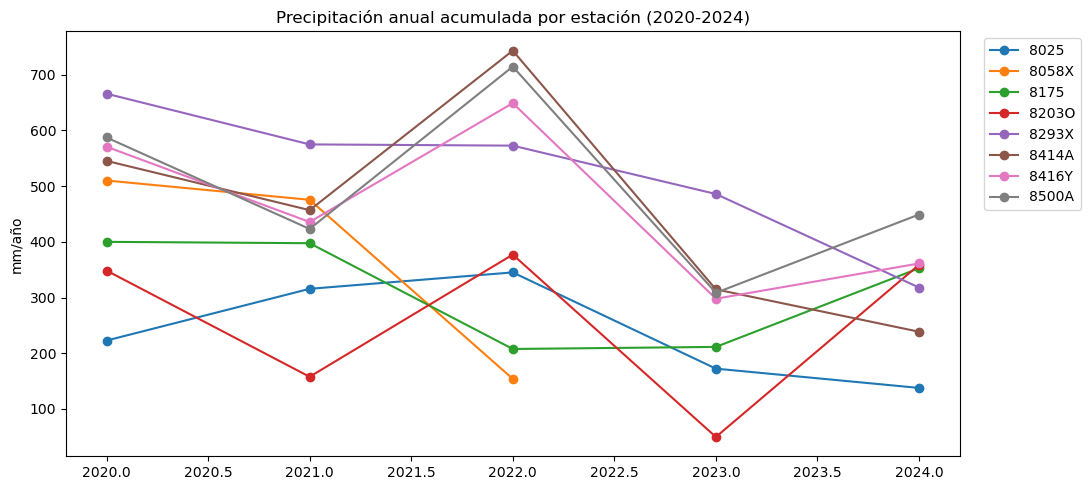

In [10]:
df["año"] = df["fecha"].dt.year
anual = df.groupby(["indicativo", "año"])["prec"].sum().reset_index()

fig, ax = plt.subplots(figsize=(11, 5))
for est in anual["indicativo"].unique():
    sub = anual[anual["indicativo"] == est]
    ax.plot(sub["año"], sub["prec"], marker="o", label=est)
ax.set_title("Precipitación anual acumulada por estación (2020-2024)")
ax.set_ylabel("mm/año")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

El total anual oculta el evento. En la DANA cayeron en pocas horas cantidades comparables a varios meses, pero al sumar todo el año queda diluido. Además, la lluvia extrema cayó en una zona geográfica muy concreta y tus estaciones no estaban allí.

## Heatmap de precipitación mensual

Se agregan las precipitaciones por estación y mes para visualizar patrones temporales y detectar episodios excepcionales.

Esta representación facilita la identificación de eventos extremos que pueden quedar ocultos al analizar únicamente acumulados anuales.

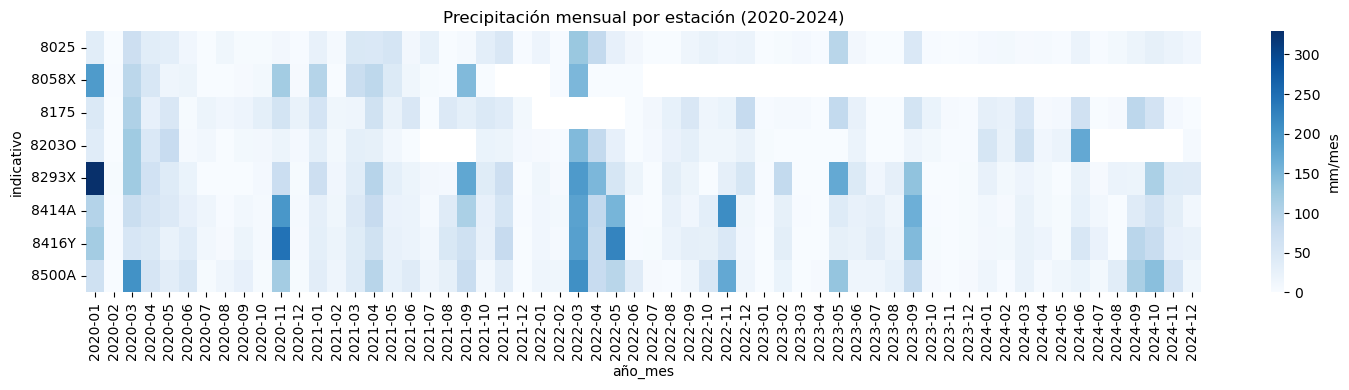

In [11]:
df["año_mes"] = df["fecha"].dt.to_period("M").astype(str)
heat = (df.groupby(["indicativo", "año_mes"])["prec"]
          .sum()
          .unstack("año_mes"))

fig, ax = plt.subplots(figsize=(15, 4))
sns.heatmap(heat, cmap="Blues", cbar_kws={"label": "mm/mes"}, ax=ax)
ax.set_title("Precipitación mensual por estación (2020-2024)")
plt.tight_layout()
plt.show()

Se puede observar cómo destaca en 8293X (Utiel) en enero de 2020. Eso fue el temporal Gloria — otro evento extremo que también causó destrozos en Valencia. Es un evento similar a la DANA de 2025 pero cuatro años antes.

Una agregación mensual no es suficiente para identificar eventos de lluvia torrencial. Se necesitaría una resolución diaria al menos. Otra justificación más para SAIH.

## Episodios extremos del periodo

Se identifican los diez registros diarios con mayor precipitación observada en el conjunto histórico.

Este análisis permite contextualizar la magnitud de la DANA de octubre de 2024 frente al resto del periodo estudiado.

In [12]:
top_dias = df.nlargest(10, "prec")[
    ["fecha", "indicativo", "prec", "tmed", "tmin", "tmax"]
]
top_dias

,fecha,indicativo,prec,tmed,tmin,tmax
5594,2020-01-20,8293X,165.8,5.0,2.7,7.4
10078,2022-05-03,8416Y,165.0,14.2,12.8,15.5
11142,2020-03-31,8500A,150.0,9.8,6.8,12.9
8443,2022-11-11,8414A,148.4,14.8,13.9,15.8
5593,2020-01-19,8293X,124.0,8.9,5.7,12.1
2381,2021-09-21,8058X,121.8,19.0,16.1,22.0
11862,2022-03-21,8500A,115.6,12.5,11.3,13.7
12097,2022-11-11,8500A,114.4,15.2,13.9,16.4
8251,2022-05-03,8414A,108.6,14.3,12.8,15.8
6204,2021-09-22,8293X,105.6,20.0,16.6,23.5
